## A1. Load and explore the dataset
Load the generated dataset and check its basic statistics before applying any normalisation.

In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
  
rng = np.random.default_rng(seed=42)   # fixed — do not change 
n   = 200 
  
# Normal distribution: systolic blood pressure (mm Hg) 
bp   = rng.normal(loc=120, scale=15, size=n).round(1) 
  
# Gamma distribution: patient waiting time (minutes) 
wait = rng.gamma(shape=2, scale=30, size=n).round(1) 
  
# Inject 5 high outliers into each column 
bp[rng.choice(n, 5, replace=False)]   = rng.uniform(190, 230, 5).round(1) 
wait[rng.choice(n, 5, replace=False)] = rng.uniform(350, 500, 5).round(1) 
  
df = pd.DataFrame({"bp": bp, "wait": wait}) 
df.to_csv("normalisation_data.csv", index=False) 
print(df.describe().round(2)) 
df.head() 

           bp    wait
count  200.00  200.00
mean   121.72   72.46
std     18.72   74.97
min     88.00    2.80
25%    110.40   32.38
50%    119.80   54.75
75%    129.43   87.48
max    221.10  488.70


,bp,wait
0,124.6,64.2
1,104.4,53.6
2,131.3,5.2
3,134.1,23.9
4,90.7,23.1


## A2. Python Implementation of Normalisation Techniques

The following code applies five different normalisation techniques to the dataset. Each technique transforms the data using a different formula while preserving the relative information in the column.

In [3]:
s = df["bp"]                                      # or df["wait"] 
  
bp_min  = s - s.min()                            # min scaling 
bp_max  = s / s.max()                            # max scaling 
bp_mm   = (s - s.min()) / (s.max() - s.min())   # min-max 
bp_z    = (s - s.mean()) / s.std()               # z-score 
  
Q1, Q3  = s.quantile(0.25), s.quantile(0.75) 
bp_iqr  = (s - s.median()) / (Q3 - Q1)          # IQR / robust

### Observation

Each normalisation method changes the scale of the data differently. Min-Max scaling limits values to the range [0,1], Z-score standardises the data using mean and standard deviation, while Robust scaling uses the median and IQR, making it more suitable for datasets containing outliers.

## A3.  Plotting: Histogram + Box Plot Side by Side After Each Normalisation

### 1.Min Scaling

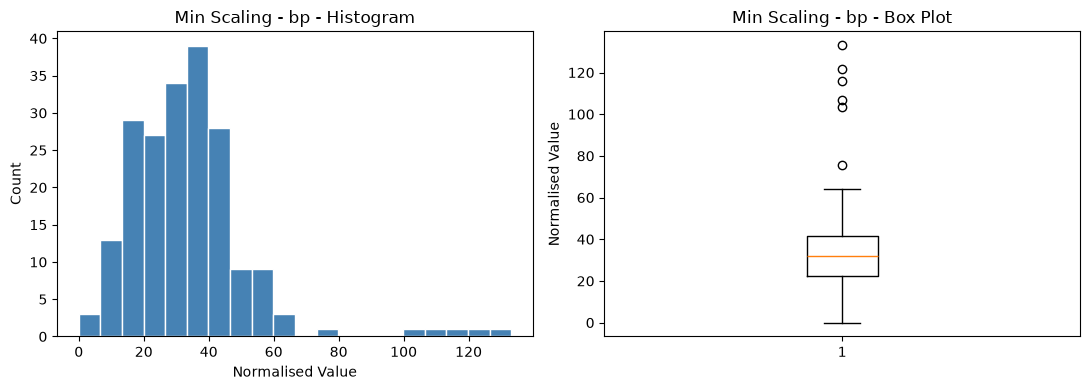

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(bp_min, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Min Scaling - bp - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(bp_min)
ax2.set_title("Min Scaling - bp - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

### 2.Max Scaling

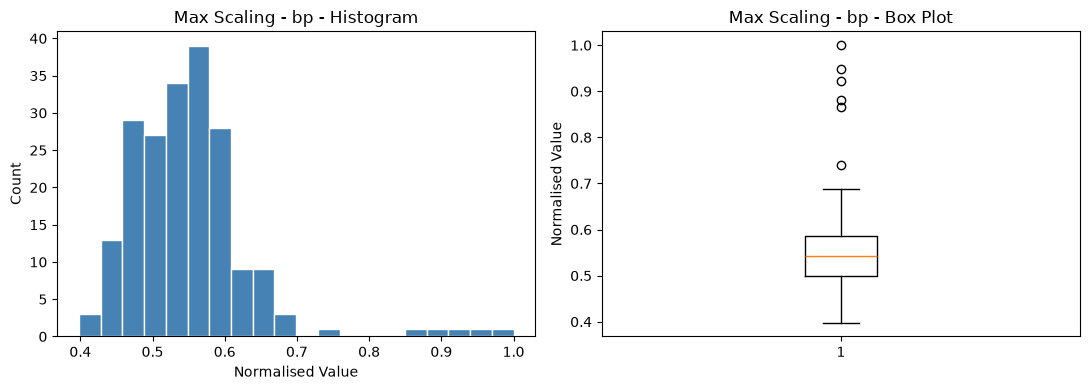

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(bp_max, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Max Scaling - bp - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(bp_max)
ax2.set_title("Max Scaling - bp - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

### 3.Min-Max Scaling

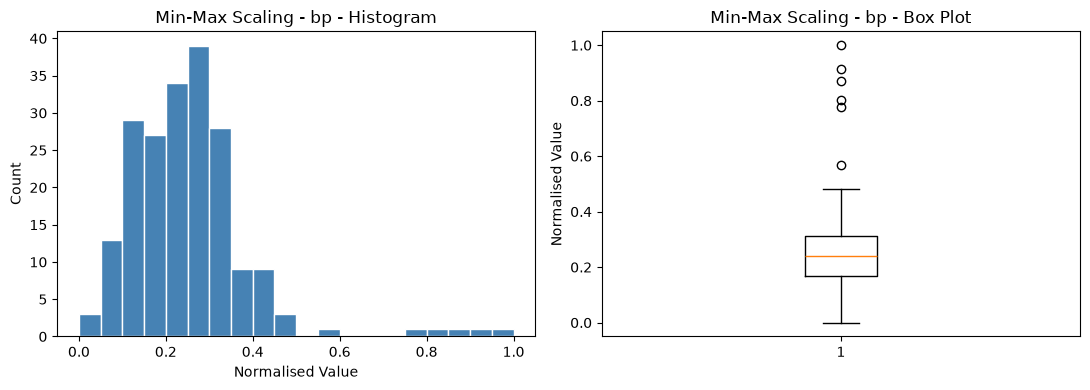

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(bp_mm, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Min-Max Scaling - bp - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(bp_mm)
ax2.set_title("Min-Max Scaling - bp - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

### 4.Z-Score Scaling

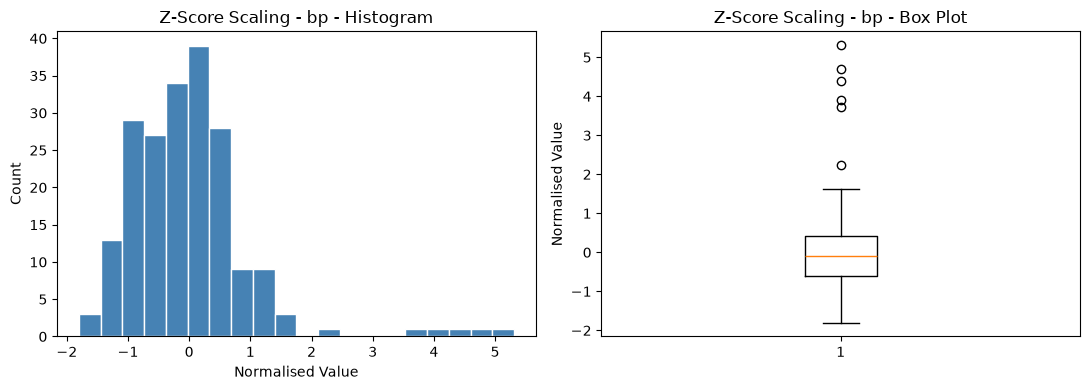

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(bp_z, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Z-Score Scaling - bp - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(bp_z)
ax2.set_title("Z-Score Scaling - bp - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

### 5.Robust(IQR) Scaling

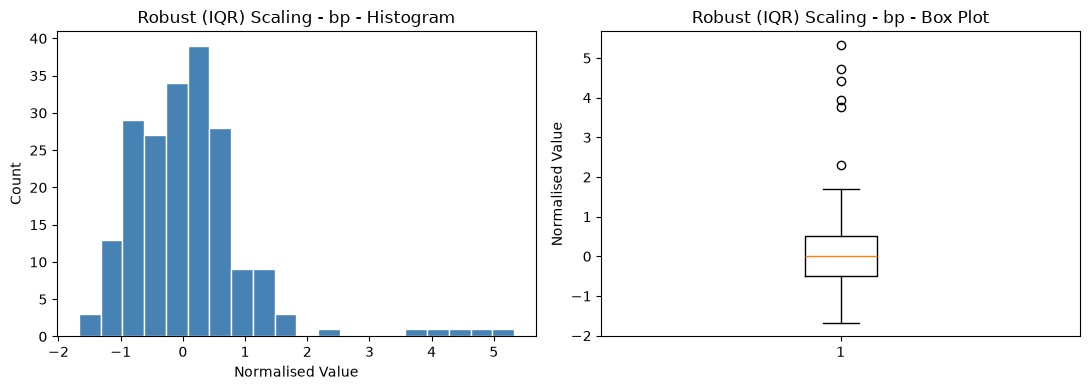

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(bp_iqr, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Robust (IQR) Scaling - bp - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(bp_iqr)
ax2.set_title("Robust (IQR) Scaling - bp - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

## A4. Quick Statistics After Normalisation

The summary statistics of the normalised data are calculated to compare how each normalisation technique changes the scale and distribution of the original data.

## B1. Load and Explore the Raw Data

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("normalisation_data.csv")

print("Shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nSummary statistics:")
print(df.describe().round(2))

Shape: (200, 2)

First 5 rows:
      bp  wait
0  124.6  64.2
1  104.4  53.6
2  131.3   5.2
3  134.1  23.9
4   90.7  23.1

Summary statistics:
           bp    wait
count  200.00  200.00
mean   121.72   72.46
std     18.72   74.97
min     88.00    2.80
25%    110.40   32.38
50%    119.80   54.75
75%    129.43   87.48
max    221.10  488.70


### B2

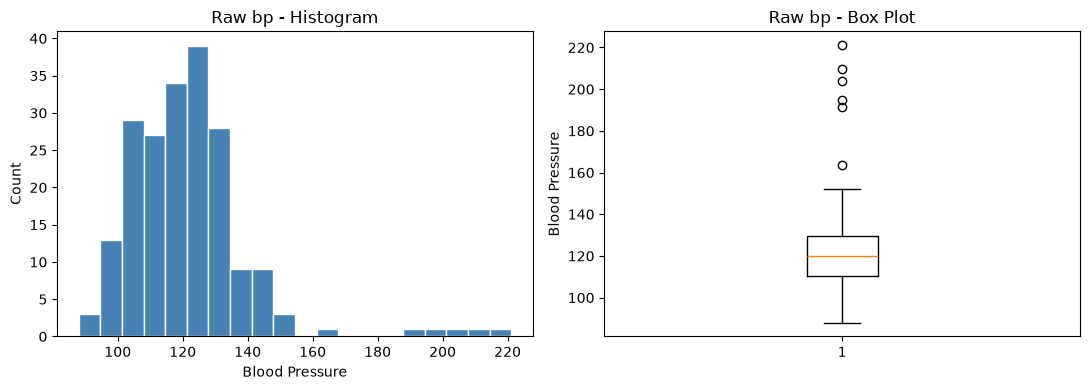

In [40]:
fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(df["bp"], bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Raw bp - Histogram")
ax1.set_xlabel("Blood Pressure")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(df["bp"])
ax2.set_title("Raw bp - Box Plot")
ax2.set_ylabel("Blood Pressure")

plt.tight_layout()
plt.show()

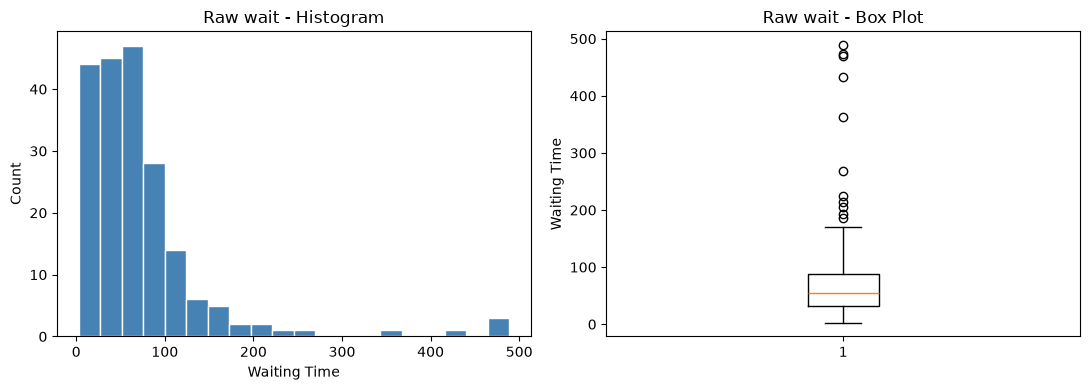

In [36]:
fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(df["wait"], bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Raw wait - Histogram")
ax1.set_xlabel("Waiting Time")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(df["wait"])
ax2.set_title("Raw wait - Box Plot")
ax2.set_ylabel("Waiting Time")

plt.tight_layout()
plt.show()

### B3

In [12]:
bp_skew = df["bp"].skew()
wait_skew = df["wait"].skew()

print("Skewness of bp   :", round(bp_skew, 3))
print("Skewness of wait :", round(wait_skew, 3))

Skewness of bp   : 2.203
Skewness of wait : 3.445


### B4-Min Scaling

In [47]:
bp_min = df["bp"] - df["bp"].min()
wait_min = df["wait"] - df["wait"].min()

print("BP Min Scaling")
print("Min:", bp_min.min())
print("Max:", bp_min.max())

print("\nWait Min Scaling")
print("Min:", wait_min.min())
print("Max:", wait_min.max())

BP Min Scaling
Min: 0.0
Max: 133.1

Wait Min Scaling
Min: 0.0
Max: 485.9


### B5 - Histogram + Box Plot

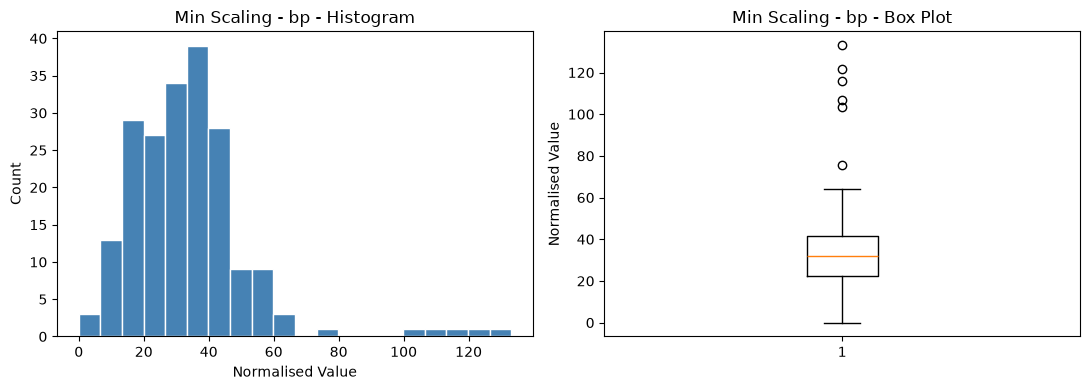

In [48]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.hist(bp_min, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Min Scaling - bp - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

ax2.boxplot(bp_min)
ax2.set_title("Min Scaling - bp - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

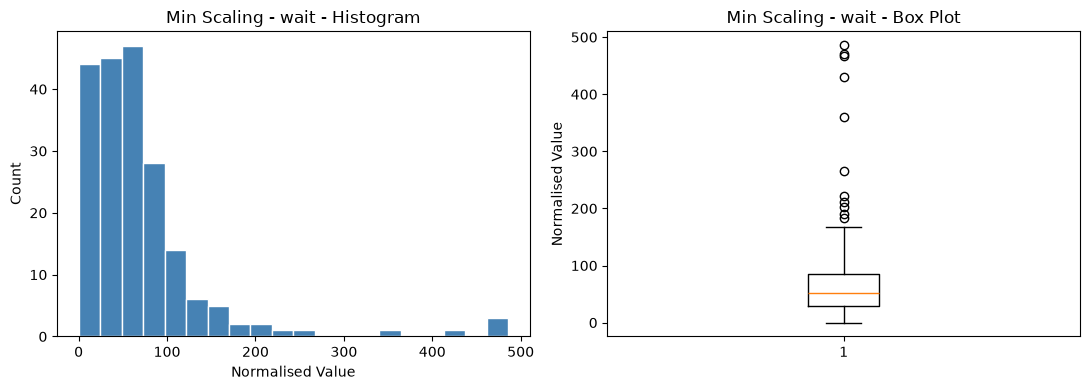

In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.hist(wait_min, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Min Scaling - wait - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

ax2.boxplot(wait_min)
ax2.set_title("Min Scaling - wait - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

### B6. Observation

Min Scaling is useful when we want all values to start from 0 while keeping the original distribution shape. One limitation is that it does not set the maximum to a fixed value and does not reduce the effect of outliers.

# B7 Apply Max Scaling

In [13]:
bp_max = df["bp"] / df["bp"].max()
wait_max = df["wait"] / df["wait"].max()

print("BP Max Scaling")
print("Min:", round(bp_max.min(), 4))
print("Max:", round(bp_max.max(), 4))

print("\nWait Max Scaling")
print("Min:", round(wait_max.min(), 4))
print("Max:", round(wait_max.max(), 4))

BP Max Scaling
Min: 0.398
Max: 1.0

Wait Max Scaling
Min: 0.0057
Max: 1.0


# B8 Histogram + Box Plot

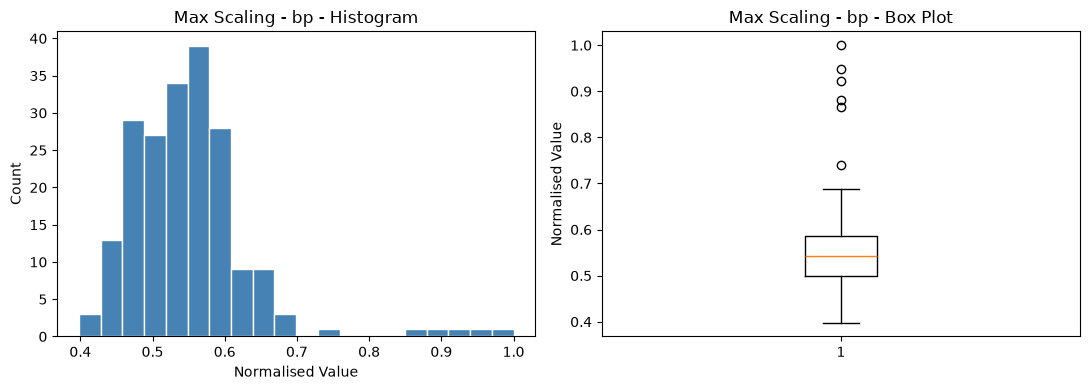

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(bp_max, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Max Scaling - bp - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(bp_max)
ax2.set_title("Max Scaling - bp - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

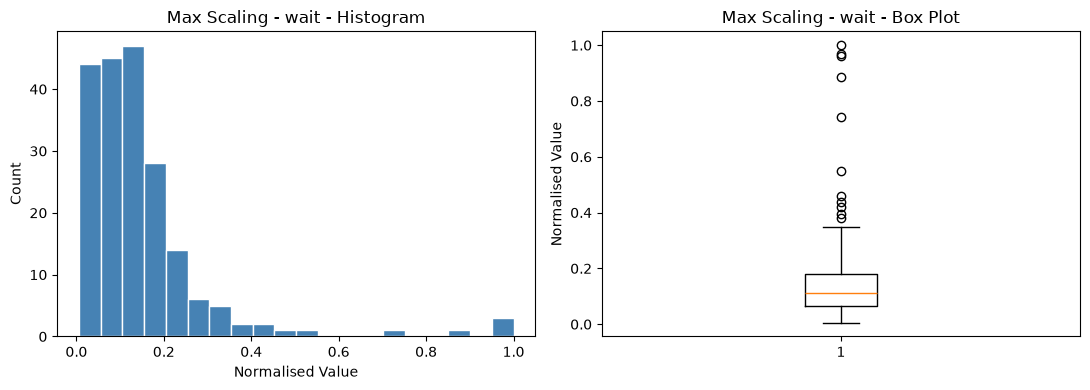

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(wait_max, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Max Scaling - wait - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(wait_max)
ax2.set_title("Max Scaling - wait - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

# B9. Apply Min-Max Scaling

In [16]:
bp_mm = (df["bp"] - df["bp"].min()) / (df["bp"].max() - df["bp"].min())
wait_mm = (df["wait"] - df["wait"].min()) / (df["wait"].max() - df["wait"].min())

print("BP Min-Max Scaling")
print("Min:", bp_mm.min())
print("Max:", bp_mm.max())

print("\nWait Min-Max Scaling")
print("Min:", wait_mm.min())
print("Max:", wait_mm.max())

BP Min-Max Scaling
Min: 0.0
Max: 1.0

Wait Min-Max Scaling
Min: 0.0
Max: 1.0


# B10. Plot Histogram + Box Plot

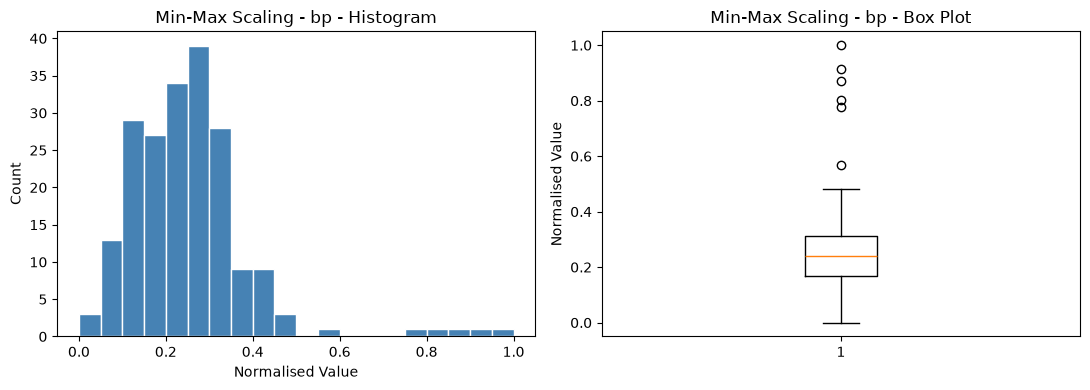

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(bp_mm, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Min-Max Scaling - bp - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(bp_mm)
ax2.set_title("Min-Max Scaling - bp - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

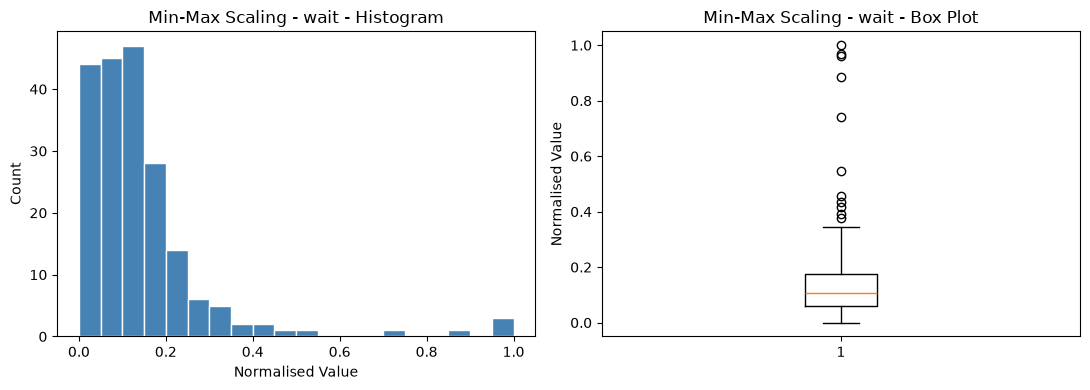

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(wait_mm, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Min-Max Scaling - wait - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(wait_mm)
ax2.set_title("Min-Max Scaling - wait - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

# B11. Why is Min-Max sensitive to outliers?

### Min-Max scaling is sensitive to outliers because it uses the minimum and maximum values of the dataset. If a value of 10,000 is added to the `wait` column, the maximum becomes 10,000. This greatly increases the range, causing most of the non-outlier values to be compressed very close to 0 after scaling.

### B12 — Z-Score Normalisation

In [41]:
bp_z = (df["bp"] - df["bp"].mean()) / df["bp"].std()
wait_z = (df["wait"] - df["wait"].mean()) / df["wait"].std()

print("BP")
print("Mean:", bp_z.mean())
print("Std :", bp_z.std())

print("\nWait")
print("Mean:", wait_z.mean())
print("Std :", wait_z.std())

BP
Mean: 3.7747582837255325e-17
Std : 0.9999999999999999

Wait
Mean: 8.881784197001253e-18
Std : 1.0


### B13 — Histogram + Box Plot

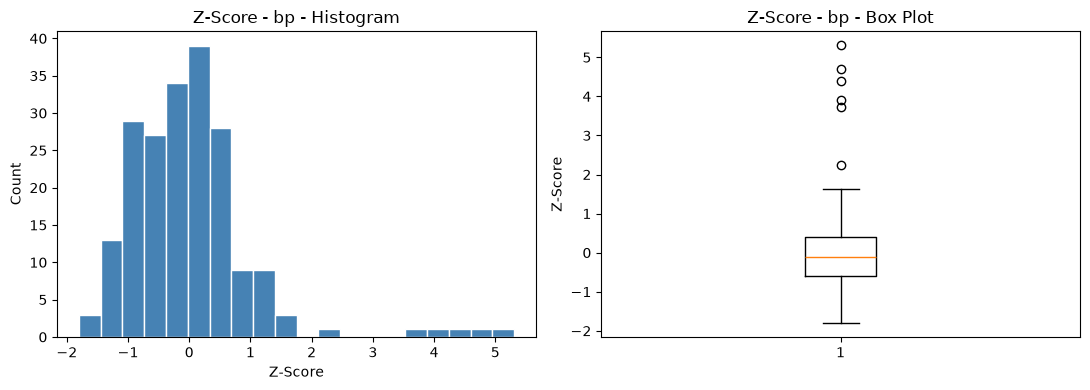

In [42]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.hist(bp_z, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Z-Score - bp - Histogram")
ax1.set_xlabel("Z-Score")
ax1.set_ylabel("Count")

ax2.boxplot(bp_z)
ax2.set_title("Z-Score - bp - Box Plot")
ax2.set_ylabel("Z-Score")

plt.tight_layout()
plt.show()

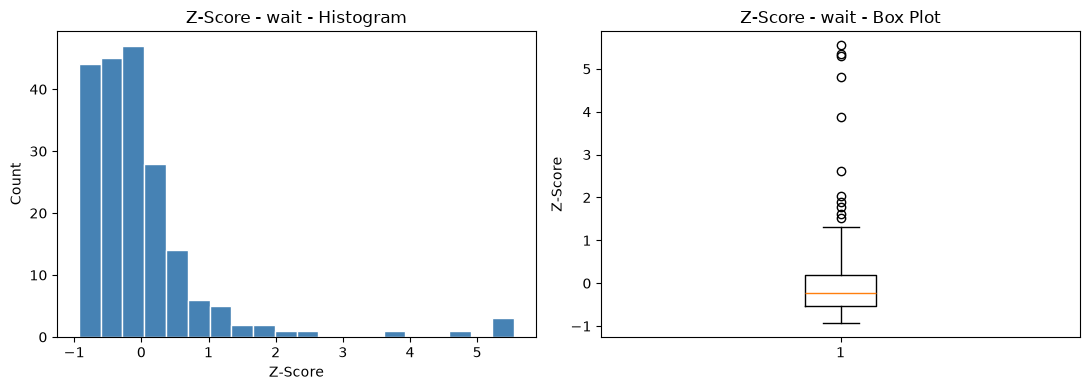

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.hist(wait_z, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Z-Score - wait - Histogram")
ax1.set_xlabel("Z-Score")
ax1.set_ylabel("Count")

ax2.boxplot(wait_z)
ax2.set_title("Z-Score - wait - Box Plot")
ax2.set_ylabel("Z-Score")

plt.tight_layout()
plt.show()

### B14 — Raw BP vs Z-Score BP

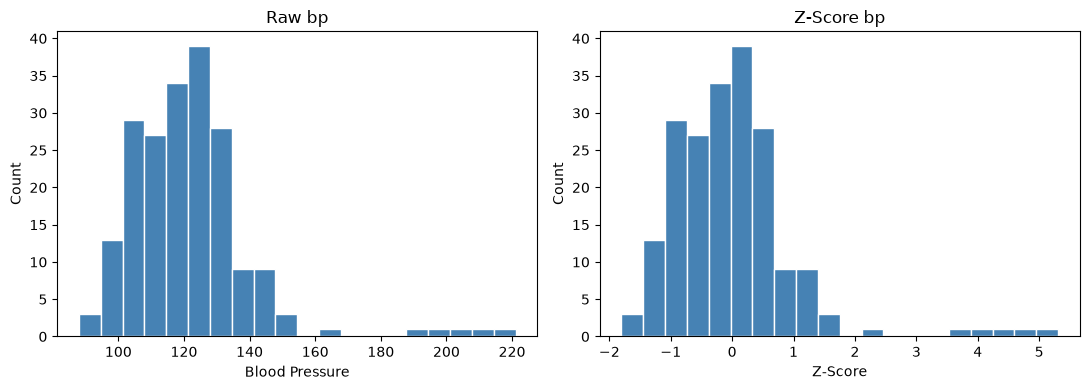

In [46]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Raw bp
ax1.hist(df["bp"], bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Raw bp")
ax1.set_xlabel("Blood Pressure")
ax1.set_ylabel("Count")

# Z-score bp
ax2.hist(bp_z, bins=20, color="steelblue", edgecolor="white")
ax2.set_title("Z-Score bp")
ax2.set_xlabel("Z-Score")
ax2.set_ylabel("Count")

plt.tight_layout()
plt.show()

# B15. Apply IQR Scaling

In [19]:
bp_median = df["bp"].median()
bp_q1 = df["bp"].quantile(0.25)
bp_q3 = df["bp"].quantile(0.75)
bp_iqr = (df["bp"] - bp_median) / (bp_q3 - bp_q1)

wait_median = df["wait"].median()
wait_q1 = df["wait"].quantile(0.25)
wait_q3 = df["wait"].quantile(0.75)
wait_iqr = (df["wait"] - wait_median) / (wait_q3 - wait_q1)

print("BP")
print("Median:", bp_iqr.median())
print("IQR:", round(bp_iqr.quantile(0.75) - bp_iqr.quantile(0.25), 4))

print("\nWait")
print("Median:", wait_iqr.median())
print("IQR:", round(wait_iqr.quantile(0.75) - wait_iqr.quantile(0.25), 4))

BP
Median: -3.7339922820400773e-16
IQR: 1.0

Wait
Median: 0.0
IQR: 1.0


# B16. Histogram + Box Plot

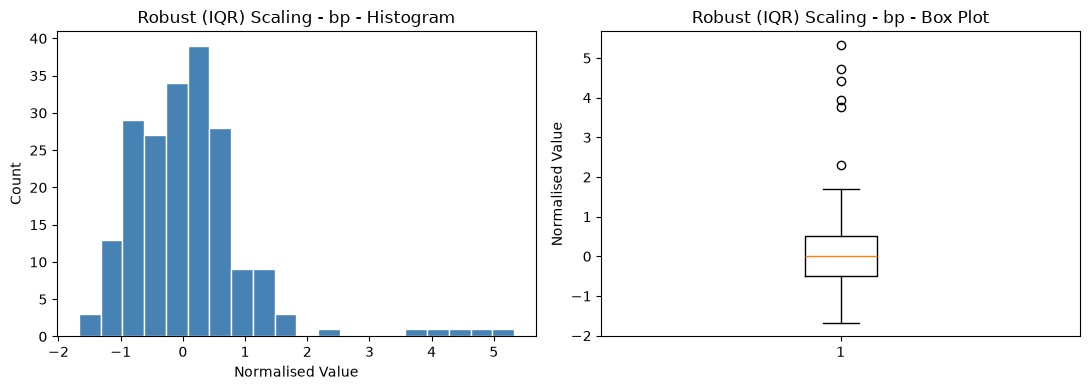

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(bp_iqr, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Robust (IQR) Scaling - bp - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(bp_iqr)
ax2.set_title("Robust (IQR) Scaling - bp - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

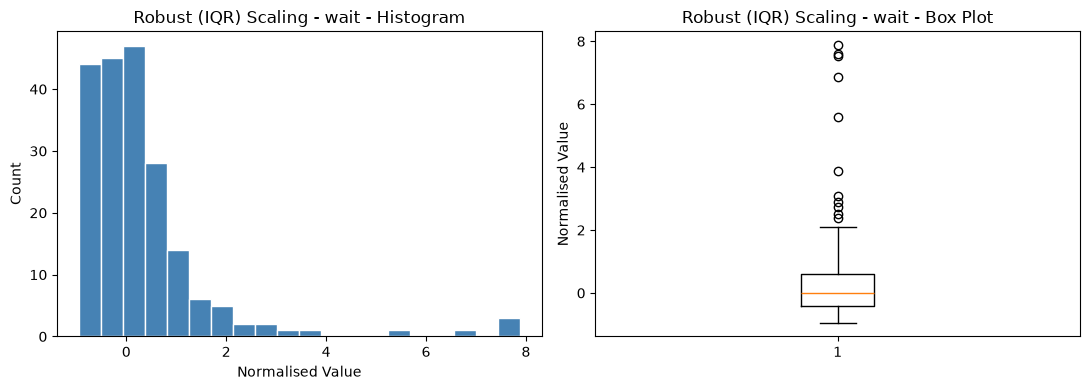

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
ax1.hist(wait_iqr, bins=20, color="steelblue", edgecolor="white")
ax1.set_title("Robust (IQR) Scaling - wait - Histogram")
ax1.set_xlabel("Normalised Value")
ax1.set_ylabel("Count")

# Box Plot
ax2.boxplot(wait_iqr)
ax2.set_title("Robust (IQR) Scaling - wait - Box Plot")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

### B16. Observation

The IQR-scaled box plots show that the outliers can appear farther away from the main box compared with Z-score scaling. This happens because IQR is based on the middle 50% of the data and is less affected by extreme values. Therefore, the main body remains relatively compact while extreme observations receive larger scaled values.

In [22]:
wait_z = (df["wait"] - df["wait"].mean()) / df["wait"].std()

print(wait_z.head())

0   -0.110237
1   -0.251626
2   -0.897215
3   -0.647783
4   -0.658454
Name: wait, dtype: float64


### B17. Compare IQR vs Z-score for wait

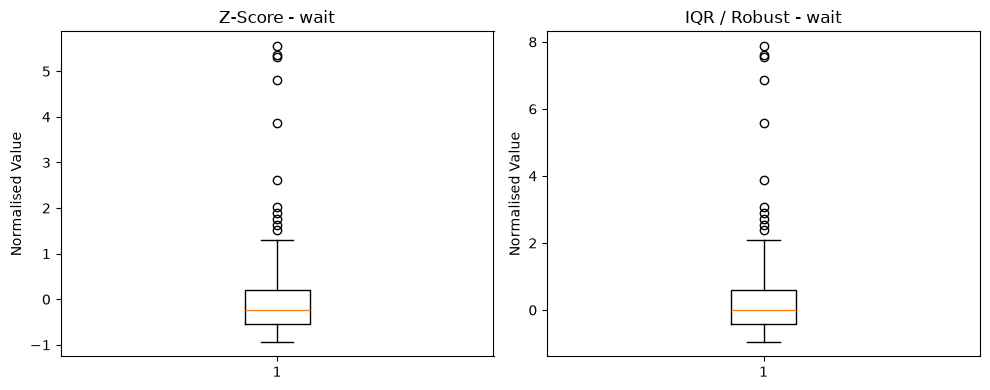

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# Z-score
ax1.boxplot(wait_z)
ax1.set_title("Z-Score - wait")
ax1.set_ylabel("Normalised Value")

# IQR
ax2.boxplot(wait_iqr)
ax2.set_title("IQR / Robust - wait")
ax2.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

In [24]:
# Load the raw data
df = pd.read_csv("normalisation_data.csv")

# Raw bp column
s = df["bp"]

# 1. Min Scaling
bp_min = s - s.min()

# 2. Max Scaling
bp_max = s / s.max()

# 3. Min-Max Scaling
bp_mm = (s - s.min()) / (s.max() - s.min())

# 4. Z-Score Scaling
bp_z = (s - s.mean()) / s.std()

# 5. IQR / Robust Scaling
Q1 = s.quantile(0.25)
Q3 = s.quantile(0.75)

bp_iqr = (s - s.median()) / (Q3 - Q1)

print("All bp normalised versions created successfully.")

All bp normalised versions created successfully.


In [25]:
# Load the raw data
df = pd.read_csv("normalisation_data.csv")

# Raw bp column
s = df["bp"]

# 1. Min Scaling
bp_min = s - s.min()

# 2. Max Scaling
bp_max = s / s.max()

# 3. Min-Max Scaling
bp_mm = (s - s.min()) / (s.max() - s.min())

# 4. Z-Score Scaling
bp_z = (s - s.mean()) / s.std()

# 5. IQR / Robust Scaling
Q1 = s.quantile(0.25)
Q3 = s.quantile(0.75)

bp_iqr = (s - s.median()) / (Q3 - Q1)

print("All bp normalised versions created successfully.")

All bp normalised versions created successfully.


### B18. Compare all five normalisations for bp

In [26]:
bp_comparison = pd.DataFrame({
    "raw": df["bp"],
    "min_scale": bp_min,
    "max_scale": bp_max,
    "min_max": bp_mm,
    "z": bp_z,
    "iqr": bp_iqr
})

bp_comparison.describe().round(3)

,raw,min_scale,max_scale,min_max,z,iqr
count,200.000,200.000,200.000,200.000,200.000,200.000
mean,121.723,33.723,0.551,0.253,0.000,0.101
std,18.717,18.717,0.085,0.141,1.000,0.984
min,88.000,0.000,0.398,0.000,-1.802,-1.671
25%,110.400,22.400,0.499,0.168,-0.605,-0.494
50%,119.800,31.800,0.542,0.239,-0.103,-0.000
75%,129.425,41.425,0.585,0.311,0.411,0.506
max,221.100,133.100,1.000,1.000,5.309,5.325


### B19. Five box plots for wait

In [28]:
# Raw wait column
s_wait = df["wait"]

# 1. Min Scaling
wait_min = s_wait - s_wait.min()

# 2. Max Scaling
wait_max = s_wait / s_wait.max()

# 3. Min-Max Scaling
wait_mm = (s_wait - s_wait.min()) / (s_wait.max() - s_wait.min())

# 4. Z-Score Scaling
wait_z = (s_wait - s_wait.mean()) / s_wait.std()

# 5. IQR / Robust Scaling
Q1_wait = s_wait.quantile(0.25)
Q3_wait = s_wait.quantile(0.75)

wait_iqr = (s_wait - s_wait.median()) / (Q3_wait - Q1_wait)

print("All wait normalised versions created successfully.")

All wait normalised versions created successfully.


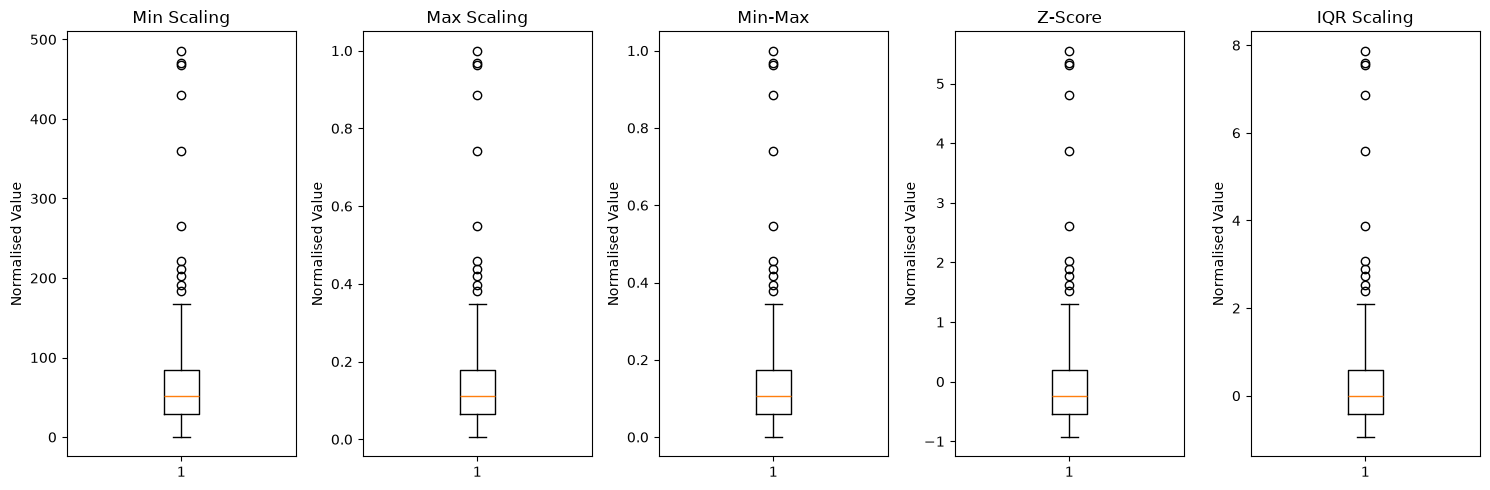

In [29]:
fig, axes = plt.subplots(1, 5, figsize=(15, 5))

data = [wait_min, wait_max, wait_mm, wait_z, wait_iqr]
titles = ["Min Scaling", "Max Scaling", "Min-Max", "Z-Score", "IQR Scaling"]

for ax, values, title in zip(axes, data, titles):
    ax.boxplot(values)
    ax.set_title(title)
    ax.set_ylabel("Normalised Value")

plt.tight_layout()
plt.show()

### B19. Observation

Min-Max scaling most strongly compresses the main body of the `wait` data because the extreme maximum determines the scaling range. IQR scaling makes the outliers look the most extreme because it uses the middle 50% of the data for scaling and is less affected by extreme values.

### B20. Final Comparison

For a scale-sensitive machine learning model such as K-NN, I would choose IQR/Robust Scaling when the dataset contains outliers. It uses the median and IQR, so extreme values have less influence on the scaling. Z-score scaling is also useful, but it uses the mean and standard deviation, which can be affected by outliers. Min-Max scaling maps values between 0 and 1, but it is sensitive to extreme values because it depends on the minimum and maximum. Therefore, IQR/Robust Scaling is a better choice when the dataset contains many outliers.

### B21  Generate a new column: bimodal = np.concatenate([rng.normal(50,5,100), rng.normal(150,5,100)]). Apply all five normalisations to it. For each, draw a histogram. Which normalisation preserves the bimodal shape most clearly? Which technique would be misleading if you assumed the output was always unimodal? 

In [30]:
bimodal = np.concatenate([
    rng.normal(50, 5, 100),
    rng.normal(150, 5, 100)
])

bimodal_min = bimodal - bimodal.min()
bimodal_max = bimodal / bimodal.max()
bimodal_mm = (bimodal - bimodal.min()) / (bimodal.max() - bimodal.min())
bimodal_z = (bimodal - bimodal.mean()) / bimodal.std()

q1 = np.percentile(bimodal, 25)
q3 = np.percentile(bimodal, 75)
bimodal_iqr = (bimodal - np.median(bimodal)) / (q3 - q1)

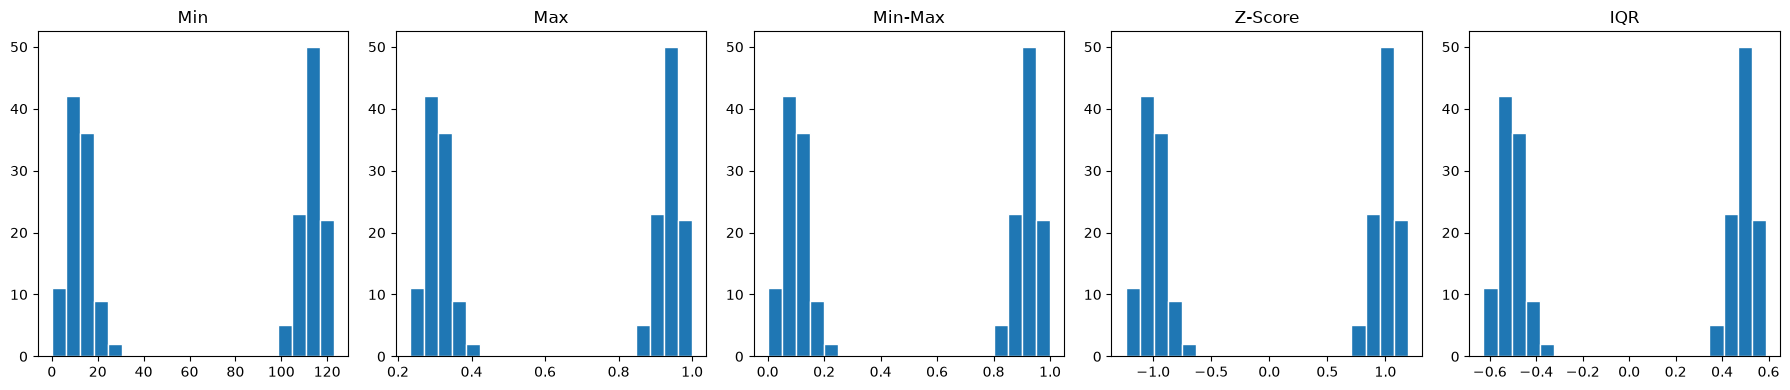

In [31]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

data = [bimodal_min, bimodal_max, bimodal_mm, bimodal_z, bimodal_iqr]
titles = ["Min", "Max", "Min-Max", "Z-Score", "IQR"]

for ax, values, title in zip(axes, data, titles):
    ax.hist(values, bins=20, edgecolor="white")
    ax.set_title(title)

plt.tight_layout()
plt.show()

### B22. Without using any pandas or NumPy normalisation helper: write your own functions min_max_scale(arr) and z_score_scale(arr) using only basic Python arithmetic. Verify that their output matches your earlier pandas results for the bp column (hint: np.allclose is useful here). 

In [32]:
def min_max_scale(arr):
    minimum = min(arr)
    maximum = max(arr)
    
    return [(x - minimum) / (maximum - minimum) for x in arr]


def z_score_scale(arr):
    n = len(arr)
    mean = sum(arr) / n
    
    variance = sum((x - mean) ** 2 for x in arr) / (n - 1)
    std = variance ** 0.5
    
    return [(x - mean) / std for x in arr]

In [33]:
bp_manual_mm = min_max_scale(df["bp"].tolist())
bp_manual_z = z_score_scale(df["bp"].tolist())

print("Min-Max:", np.allclose(bp_manual_mm, bp_mm))
print("Z-Score:", np.allclose(bp_manual_z, bp_z))

Min-Max: True
Z-Score: True


### B23 — Log Transformation

In [34]:
log_wait = np.log1p(df["wait"])

print(log_wait.head())

0    4.177459
1    4.000034
2    1.824549
3    3.214868
4    3.182212
Name: wait, dtype: float64
